# Clasificador de países con GRU/LSTM

**Problema:** dada una pregunta de cultura general latinoamericana, predecir **a qué país se refiere**
(clasificación de texto con 18 clases).

**Modelo:** red recurrente bidireccional (GRU, y comparación con LSTM) sobre secuencias de palabras.

**Pasos del notebook**
1. Descripción del dataset
2. Análisis exploratorio
3. Limpieza y preprocesamiento
4. División en entrenamiento / validación / prueba
5. Construcción y entrenamiento de la red
6. Gráficas del entrenamiento
7. Evaluación con métricas
8. Comparación GRU vs LSTM
9. Diez (o más) predicciones de prueba
10. Guardado del modelo

In [1]:
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras

# Importamos las funciones sencillas que están en la carpeta src/
sys.path.append("src")
from datos import cargar_datos, dividir_datos, SEMILLA
from modelo import crear_vectorizador, crear_modelo

keras.utils.set_random_seed(SEMILLA)
sns.set_theme(style="whitegrid")

I0000 00:00:1792023744.596713     993 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792023745.635753     993 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Selección y descripción del dataset

El dataset (`data/dataset.xlsx`) contiene **preguntas y respuestas en español** sobre cultura de países
latinoamericanos. Columnas:

| Columna | Significado |
|---|---|
| `Entity` | Tema sobre el que trata la pregunta (ej. una especie, un plato, un lugar) |
| `Country` | País al que pertenece (**nuestra variable objetivo**) |
| `Category` | Tipo de tema: geografía, fauna, flora, tradición, plato, personaje u objeto |
| `Difficulty` | Dificultad de la pregunta: FÁCIL, INTERMEDIA o DIFÍCIL |
| `Question` | Texto de la pregunta (**nuestra entrada**) |
| `Answer` | Respuesta |

In [2]:
crudo = pd.read_excel("data/dataset.xlsx")
print("Filas y columnas:", crudo.shape)
crudo.head()

Filas y columnas: (105000, 6)


,Entity,Country,Category,Difficulty,Question,Answer
0,(entre paréntesis),colombia,public_figure,FÁCIL,¿Quiénes son los artistas que colaboran en la ...,una canción de la cantautora colombiana Shakir...
1,(entre paréntesis),colombia,public_figure,INTERMEDIA,¿Qué tipo de música es «(Entre paréntesis)»?,una canción de cumbia norteña regiomontana con...
2,(entre paréntesis),colombia,public_figure,DIFÍCIL,¿Qué se expresa en la letra de la canción «(En...,expresa las vivencias finales de una relación ...
3,+57 (canción),colombia,public_figure,FÁCIL,"¿Cuándo fue lanzada la canción ""+57""?",el 7 de noviembre de 2024
4,+57 (canción),colombia,public_figure,INTERMEDIA,¿Quiénes fueron los intérpretes que escribiero...,todos los intérpretes y Keityn


## 2. Análisis exploratorio de los datos

In [3]:
print("Valores nulos por columna:")
print(crudo.isna().sum())
print("\nFilas duplicadas:", crudo.duplicated().sum())
print("Preguntas repetidas (texto igual):", crudo["Question"].duplicated().sum())

Valores nulos por columna:
Entity        0
Country       0
Category      0
Difficulty    0
Question      0
Answer        1
dtype: int64

Filas duplicadas: 0
Preguntas repetidas (texto igual): 1290


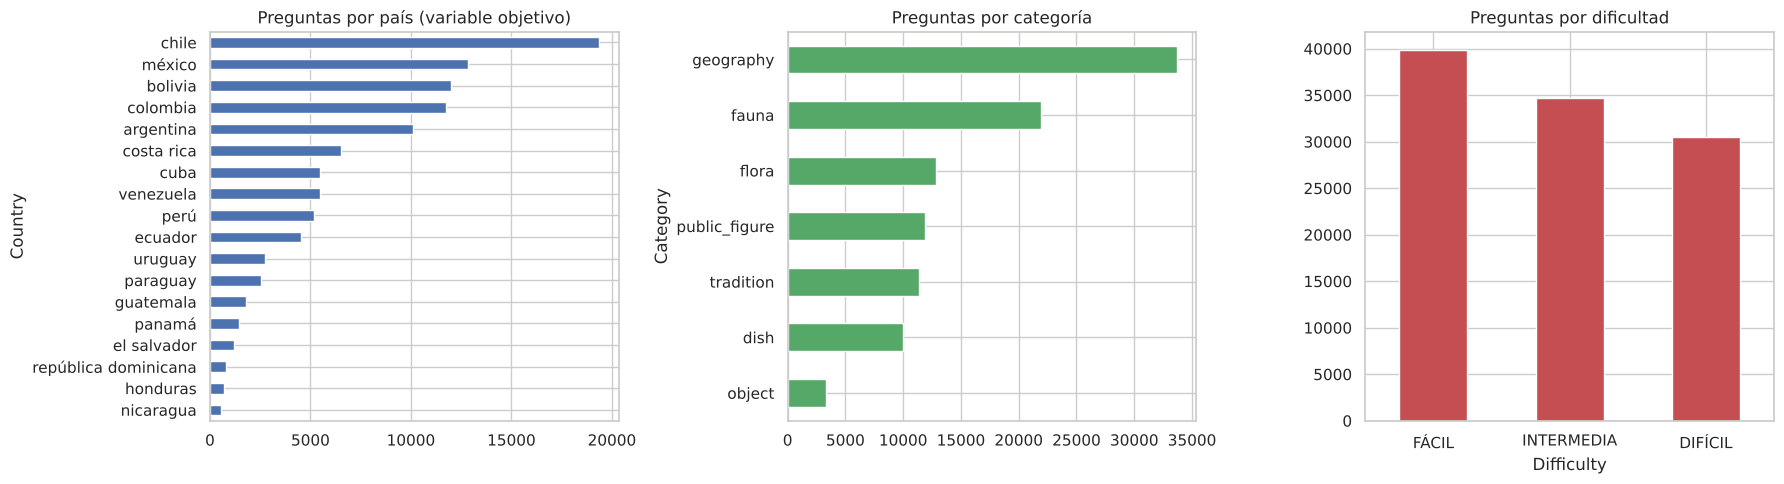

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

crudo["Country"].value_counts().plot.barh(ax=ejes[0], color="#4C72B0")
ejes[0].set_title("Preguntas por país (variable objetivo)")
ejes[0].invert_yaxis()

crudo["Category"].value_counts().plot.barh(ax=ejes[1], color="#55A868")
ejes[1].set_title("Preguntas por categoría")
ejes[1].invert_yaxis()

crudo["Difficulty"].value_counts().plot.bar(ax=ejes[2], color="#C44E52", rot=0)
ejes[2].set_title("Preguntas por dificultad")

plt.tight_layout()
plt.savefig("imagenes/eda_distribuciones.png", dpi=120)
plt.show()

**Observación:** las clases están **desbalanceadas** (Chile tiene ~19 mil preguntas y Nicaragua ~560).
Por eso más adelante usamos *pesos por clase* y la métrica **F1 macro**, que trata a todos los países por igual.

count    105000.0
mean         10.2
std           4.6
min           3.0
25%           7.0
50%           9.0
75%          13.0
max          37.0
Name: Question, dtype: float64


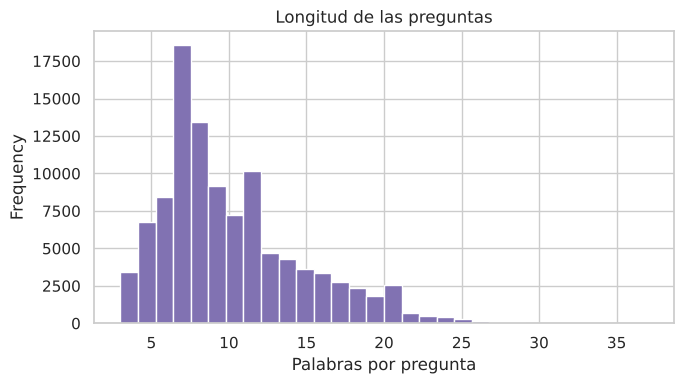

In [5]:
largo = crudo["Question"].str.split().str.len()
print(largo.describe().round(1))

plt.figure(figsize=(7, 4))
largo.plot.hist(bins=30, color="#8172B2")
plt.xlabel("Palabras por pregunta")
plt.title("Longitud de las preguntas")
plt.tight_layout()
plt.savefig("imagenes/eda_longitud.png", dpi=120)
plt.show()

Las preguntas son cortas (casi todas tienen menos de 30 palabras). Por eso en el modelo usamos **30 palabras** como largo fijo.

In [6]:
# Ejemplos de preguntas por categoría
for categoria, grupo in crudo.groupby("Category"):
    fila = grupo.sample(1, random_state=1).iloc[0]
    print(f"[{categoria:13}] ({fila['Country']}) {fila['Question']}")

[dish         ] (méxico) ¿De qué clase de árbol es la nuez de Castilla?
[fauna        ] (venezuela) ¿Qué tipo de especie es Gastrotheca williamsoni?
[flora        ] (venezuela) ¿Cuál resulta ser la altura promedio de Asterogyne yaracuyense y dónde se encuentra su hábitat?
[geography    ] (chile) ¿En qué comuna se encuentra la bahía de Cucao?
[object       ] (méxico) ¿A quién nos referimos cuando hablamos de Imelda Guillermina Barnett Díaz?
[public_figure] (chile) ¿Cuál resulta ser el nombre completo de Mónica Cerda?
[tradition    ] (argentina) ¿Qué movimiento artístico-musical fundó Daniel Tinte en 1998?


## 3. Limpieza y preprocesamiento

La función `cargar_datos()` (en `src/datos.py`) hace tres cosas: quita filas sin pregunta o país,
elimina espacios sobrantes y quita preguntas repetidas del mismo país.

El resto del preprocesamiento (pasar a minúsculas, quitar signos, convertir palabras a números y rellenar
hasta 30 posiciones) lo hace la capa `TextVectorization` que va **dentro** del modelo. Así, al guardar el
modelo, también se guarda el preprocesamiento y la app solo necesita enviarle texto.

In [7]:
df = cargar_datos()
print(f"Antes: {len(crudo)} filas  ->  Después: {len(df)} filas")

Antes: 105000 filas  ->  Después: 104689 filas


## 4. División en entrenamiento, validación y prueba (70 / 15 / 15)

Cada `Entity` aparece en 3 filas (fácil, intermedia, difícil), así que dividimos **por entidad**.
Si no lo hiciéramos, el modelo vería la misma entidad en entrenamiento y en prueba y la evaluación saldría
demasiado optimista (fuga de datos).

In [8]:
train, val, test = dividir_datos(df)
print(f"Entrenamiento: {len(train)} | Validación: {len(val)} | Prueba: {len(test)}")

# Comprobamos que ninguna entidad se repite entre conjuntos
print("Entidades compartidas train/test:", len(set(train.Entity) & set(test.Entity)))
print("Entidades compartidas train/val :", len(set(train.Entity) & set(val.Entity)))

Entrenamiento: 73282 | Validación: 15627 | Prueba: 15780
Entidades compartidas train/test: 0


Entidades compartidas train/val : 0


In [9]:
# Cada país pasa a ser un número (0, 1, 2, ...)
paises = sorted(df["Country"].unique())
pais_a_numero = {pais: i for i, pais in enumerate(paises)}

x_train = train["Question"].to_numpy(dtype=object)
x_val = val["Question"].to_numpy(dtype=object)
x_test = test["Question"].to_numpy(dtype=object)

y_train = train["Country"].map(pais_a_numero).to_numpy()
y_val = val["Country"].map(pais_a_numero).to_numpy()
y_test = test["Country"].map(pais_a_numero).to_numpy()

# Pesos: los países con pocos datos pesan más durante el entrenamiento
pesos = compute_class_weight("balanced", classes=np.arange(len(paises)), y=y_train)
pesos = dict(enumerate(pesos))
print("Peso de Chile    :", round(pesos[pais_a_numero["chile"]], 2))
print("Peso de Nicaragua:", round(pesos[pais_a_numero["nicaragua"]], 2))

Peso de Chile    : 0.3
Peso de Nicaragua: 9.72


## 5. Construcción y entrenamiento de la red neuronal

Arquitectura (definida en `src/modelo.py`):

`Texto → TextVectorization → Embedding → Dropout → Bidirectional(GRU) → Dropout → Dense(18, softmax)`

- **Embedding:** convierte cada palabra en un vector de 32 números.
- **GRU bidireccional:** lee la pregunta de izquierda a derecha y de derecha a izquierda para entender el contexto.
- **Dropout:** apaga neuronas al azar para evitar que el modelo memorice.
- **Softmax:** da una probabilidad para cada uno de los 18 países.

In [10]:
def entrenar(tipo):
    """Crea y entrena un modelo (tipo = "gru" o "lstm"). Devuelve el modelo y su historial."""
    keras.utils.set_random_seed(SEMILLA)
    vectorizador = crear_vectorizador(x_train)
    modelo = crear_modelo(vectorizador, len(paises), tipo)

    parar_temprano = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )
    historial = modelo.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=15,
        batch_size=128,
        class_weight=pesos,
        callbacks=[parar_temprano],
        verbose=2,
    )
    return modelo, historial


modelo_gru, hist_gru = entrenar("gru")
modelo_gru.summary()

Epoch 1/15


E0000 00:00:1792023762.511381     993 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


573/573 - 21s - 37ms/step - accuracy: 0.2600 - loss: 2.5718 - val_accuracy: 0.4122 - val_loss: 2.0571


Epoch 2/15


573/573 - 20s - 35ms/step - accuracy: 0.6050 - loss: 1.4470 - val_accuracy: 0.4296 - val_loss: 2.0565


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 30)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 30, 32)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        37,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,039,864 (7.78 MB)

 Trainable params: 679,954 (2.59 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,359,910 (5.19 MB)

## 6. Gráficas del entrenamiento

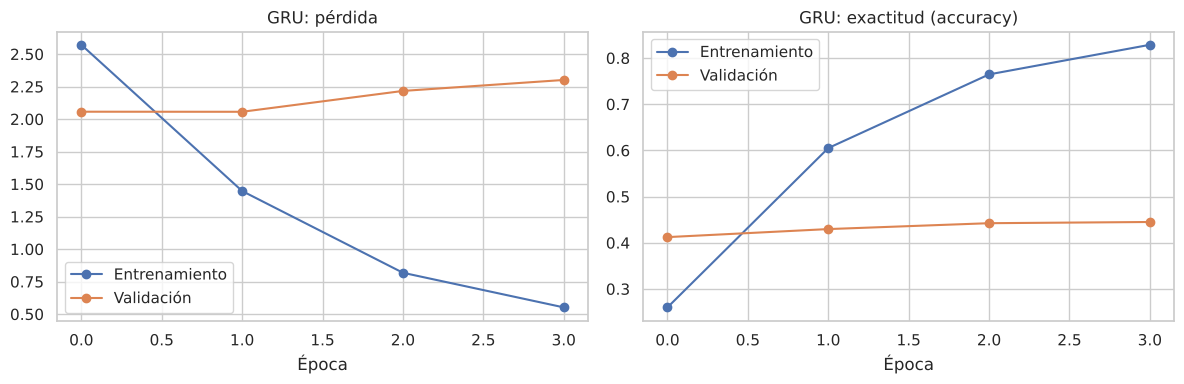

In [11]:
def graficar_historial(historial, titulo, archivo):
    h = historial.history
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    ejes[0].plot(h["loss"], label="Entrenamiento", marker="o")
    ejes[0].plot(h["val_loss"], label="Validación", marker="o")
    ejes[0].set_title(f"{titulo}: pérdida")
    ejes[0].set_xlabel("Época")
    ejes[0].legend()

    ejes[1].plot(h["accuracy"], label="Entrenamiento", marker="o")
    ejes[1].plot(h["val_accuracy"], label="Validación", marker="o")
    ejes[1].set_title(f"{titulo}: exactitud (accuracy)")
    ejes[1].set_xlabel("Época")
    ejes[1].legend()

    plt.tight_layout()
    plt.savefig(archivo, dpi=120)
    plt.show()


graficar_historial(hist_gru, "GRU", "imagenes/entrenamiento_gru.png")

## 7. Evaluación con métricas apropiadas

Usamos el conjunto de **prueba**, que el modelo nunca vio.
- **Accuracy:** porcentaje de aciertos.
- **F1 macro:** promedio del F1 de cada país; no deja que Chile (muchos datos) tape a Nicaragua (pocos).

Como referencia: si el modelo adivinara siempre "Chile", acertaría solo ~18%.

In [12]:
def evaluar(modelo):
    pred = modelo.predict(x_test, batch_size=256, verbose=0).argmax(axis=1)
    return pred, accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")


pred_gru, acc_gru, f1_gru = evaluar(modelo_gru)
print(f"GRU -> Accuracy: {acc_gru:.3f} | F1 macro: {f1_gru:.3f}")
print("Referencia (siempre el país más frecuente):",
      round((y_test == pd.Series(y_test).mode()[0]).mean(), 3))

GRU -> Accuracy: 0.429 | F1 macro: 0.362
Referencia (siempre el país más frecuente): 0.179


In [13]:
print(classification_report(y_test, pred_gru, target_names=paises, zero_division=0))

                      precision    recall  f1-score   support

           argentina       0.26      0.51      0.35      1584
             bolivia       0.41      0.37      0.39      1739
               chile       0.73      0.52      0.61      2821
            colombia       0.50      0.32      0.39      1816
          costa rica       0.71      0.41      0.52       962
                cuba       0.54      0.40      0.46       854
             ecuador       0.52      0.38      0.44       750
         el salvador       0.22      0.25      0.24       195
           guatemala       0.35      0.40      0.37       254
            honduras       0.15      0.32      0.21       114
              méxico       0.55      0.55      0.55      2013
           nicaragua       0.11      0.20      0.14        81
              panamá       0.33      0.32      0.33       224
            paraguay       0.35      0.29      0.32       412
                perú       0.26      0.36      0.30       720
repúbli

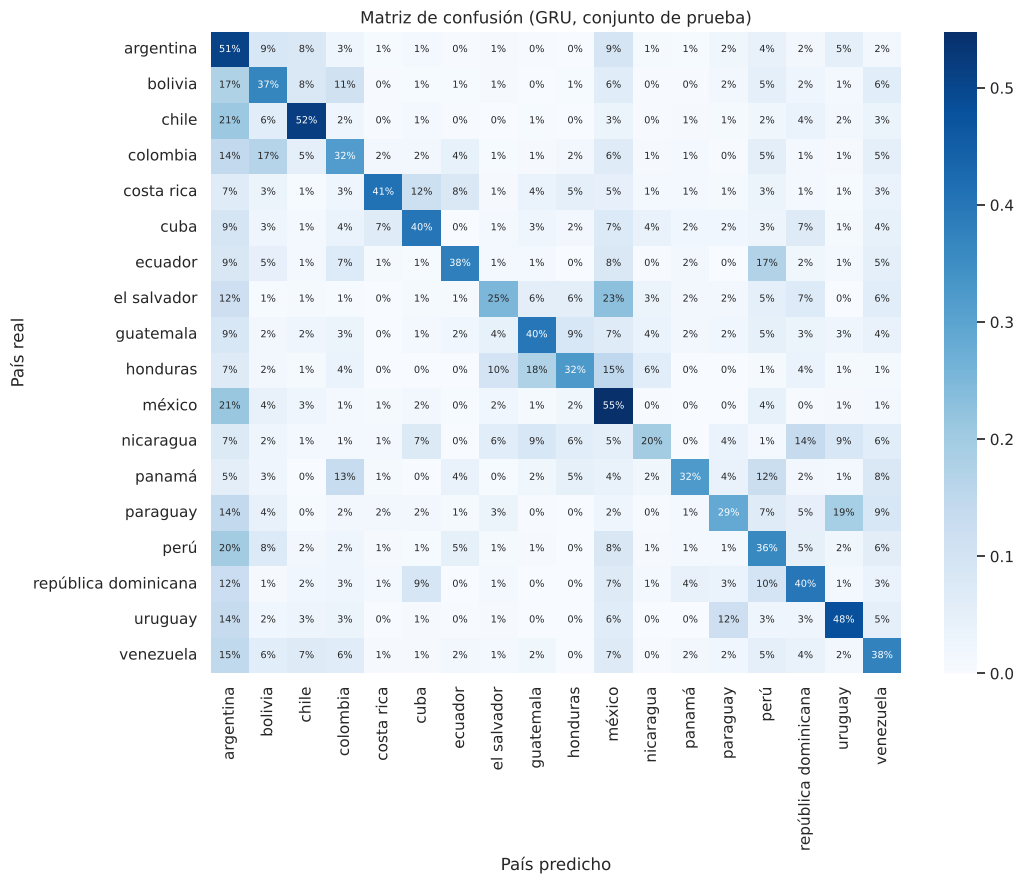

In [14]:
matriz = confusion_matrix(y_test, pred_gru, normalize="true")  # porcentaje por fila

plt.figure(figsize=(11, 9))
sns.heatmap(matriz, annot=True, fmt=".0%", cmap="Blues",
            xticklabels=paises, yticklabels=paises, annot_kws={"size": 7})
plt.xlabel("País predicho")
plt.ylabel("País real")
plt.title("Matriz de confusión (GRU, conjunto de prueba)")
plt.tight_layout()
plt.savefig("imagenes/matriz_confusion.png", dpi=120)
plt.show()

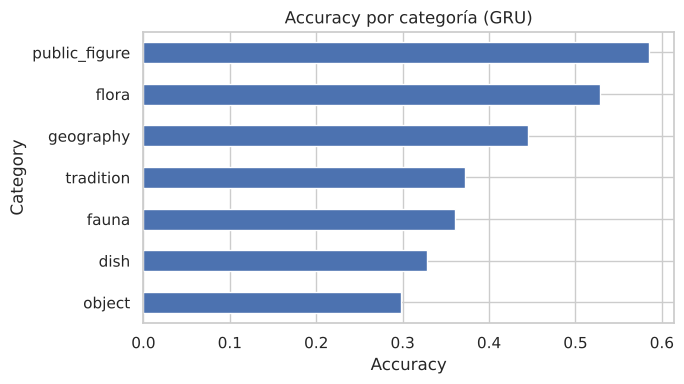

In [15]:
# ¿En qué tipo de preguntas acierta más?
resultado = test.assign(acierto=(pred_gru == y_test))
por_categoria = resultado.groupby("Category")["acierto"].mean().sort_values()

plt.figure(figsize=(7, 4))
por_categoria.plot.barh(color="#4C72B0")
plt.xlabel("Accuracy")
plt.title("Accuracy por categoría (GRU)")
plt.tight_layout()
plt.savefig("imagenes/accuracy_por_categoria.png", dpi=120)
plt.show()

**Interpretación:** el modelo acierta más en *personajes públicos*, *geografía* y *flora*, donde las preguntas
traen pistas como nombres propios o términos administrativos ("comuna", "cantón", "departamento").
Falla más en *fauna* y *platos*: preguntas como «¿Qué tipo de especie es *Calomys sorellus*?» no contienen
ninguna pista del país, así que ningún modelo de texto podría acertarlas con seguridad. Por eso el techo de
este problema no es el 100%.

## 8. Comparación GRU vs LSTM

In [16]:
modelo_lstm, hist_lstm = entrenar("lstm")
pred_lstm, acc_lstm, f1_lstm = evaluar(modelo_lstm)

comparacion = pd.DataFrame({
    "Modelo": ["GRU", "LSTM"],
    "Accuracy": [acc_gru, acc_lstm],
    "F1 macro": [f1_gru, f1_lstm],
}).round(3)
comparacion

Epoch 1/15


573/573 - 19s - 33ms/step - accuracy: 0.2767 - loss: 2.5554 - val_accuracy: 0.3640 - val_loss: 2.1484


Epoch 2/15


573/573 - 20s - 34ms/step - accuracy: 0.5771 - loss: 1.5369 - val_accuracy: 0.4298 - val_loss: 2.0137


Epoch 3/15


573/573 - 16s - 28ms/step - accuracy: 0.7361 - loss: 0.9381 - val_accuracy: 0.4353 - val_loss: 2.0879


Epoch 4/15


573/573 - 16s - 29ms/step - accuracy: 0.8078 - loss: 0.6482 - val_accuracy: 0.4417 - val_loss: 2.1904


,Modelo,Accuracy,F1 macro
0,GRU,0.429,0.362
1,LSTM,0.422,0.348


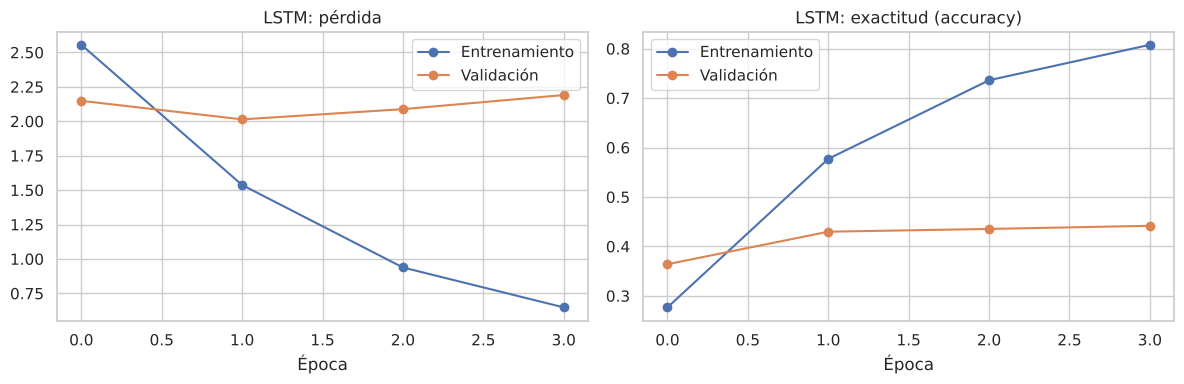

In [17]:
graficar_historial(hist_lstm, "LSTM", "imagenes/entrenamiento_lstm.png")

Ambas redes rinden de forma muy parecida. Nos quedamos con la **GRU** (o la que salga mejor en F1 macro),
porque es más ligera.

## 9. Predicciones de prueba (15 ejemplos)

In [18]:
muestra = test.sample(15, random_state=7)
probs = modelo_gru.predict(muestra["Question"].to_numpy(dtype=object), verbose=0)

tabla = pd.DataFrame({
    "Pregunta": muestra["Question"].values,
    "País real": muestra["Country"].values,
    "País predicho": [paises[i] for i in probs.argmax(axis=1)],
    "Confianza": probs.max(axis=1).round(2),
})
tabla["¿Acertó?"] = np.where(tabla["País real"] == tabla["País predicho"], "✅", "❌")

pd.set_option("display.max_colwidth", 90)
tabla

,Pregunta,País real,País predicho,Confianza,¿Acertó?
0,¿Qué clase de especie es el ugni myricoides?,colombia,chile,0.24,❌
1,¿Cuál era la categoría de Chapeltique durante la época de la colonización española?,el salvador,república dominicana,0.49,❌
2,¿Dónde se halla Echinodorus bleheri y en qué siglo se exportó como planta de acuario d...,bolivia,argentina,0.36,❌
3,¿Cuál resultó ser la primera obra que dirigió Julio Jung Duvauchelle y en qué año debu...,chile,chile,0.83,✅
4,¿En qué lugares se recolecta la Atta mexicana?,méxico,méxico,0.99,✅
5,¿Qué clase de lugar es Chihuahua en Uruguay?,uruguay,uruguay,0.96,✅
6,¿Qué es la montaña más alta del país centroamericano de Honduras?,honduras,honduras,0.61,✅
7,¿Cuál es la altitud del centro cantonal de El Pan?,ecuador,ecuador,0.82,✅
8,¿Qué característica tiene la payada?,chile,méxico,0.20,❌
9,¿Qué tipo de lugar es el golfo de Achacachi?,bolivia,venezuela,0.34,❌


## 10. Guardado del modelo entrenado

In [19]:
modelo_gru.save("modelo/modelo.keras")          # incluye el preprocesamiento de texto
with open("modelo/paises.json", "w") as f:       # lista de países en el orden del modelo
    json.dump(paises, f, ensure_ascii=False)
with open("modelo/metricas.json", "w") as f:
    json.dump({"tipo": "gru", "accuracy": acc_gru, "f1_macro": f1_gru}, f, indent=2)

# Comprobamos que el modelo guardado funciona igual que el original
from predecir import cargar_modelo, predecir
modelo_cargado, paises_cargados = cargar_modelo()
for pregunta in ["¿Qué es la cabecera cantonal del Cantón Marcabelí?",
                 "¿En qué comuna se encuentra la bahía de Cucao?",
                 "¿En qué consiste el Día de Muertos?"]:
    pais, prob = predecir(modelo_cargado, paises_cargados, pregunta)[0]
    print(f"{pregunta}\n   -> {pais} ({prob:.0%})\n")

¿Qué es la cabecera cantonal del Cantón Marcabelí?
   -> ecuador (99%)

¿En qué comuna se encuentra la bahía de Cucao?
   -> chile (94%)

¿En qué consiste el Día de Muertos?
   -> argentina (55%)



## Conclusiones

- Se construyó un clasificador de **18 países** con una **GRU bidireccional**, que supera con claridad la línea base
  de 18% (adivinar siempre el país más frecuente).
- La división **por entidad** evita fuga de datos, por lo que las métricas reflejan el rendimiento real.
- El **F1 macro** es más bajo que el accuracy por el desbalance de clases y porque muchas preguntas no mencionan nada
  que identifique al país.
- **Mejoras posibles:** usar también la respuesta como entrada, embeddings preentrenados en español o un modelo
  tipo transformer.